# Can a world model recognize an unsafe action?

Two-Rooms has two red pools between opposite-room starts and goals. A successful episode reaches the goal within 32 steps and stays outside both pools at every simulator substep. We evaluate compact PLDM and LeWM models on the same simulator tasks. This is a simulation benchmark of these training recipes.

The matched-action audit draws on [WorldOracle](https://arxiv.org/abs/2610.18826), the trajectory-level safety measures on [SafeVLA-Bench](https://arxiv.org/abs/2606.00773), and the runtime interventions on [LIBERO-Pro2.0](https://arxiv.org/abs/2610.24587).

## Run the experiment

Run from an installed checkout of this revision with the notebook and benchmark extras (`python -m pip install -e '.[notebooks,benchmark]'`). Each seed trains both models for five epochs on 192 clean episodes, then fits a failure classifier on frozen frame embeddings. The action audit starts at rest with one observed frame and an empty command history. During closed-loop control, LeWM builds up to three frames of history and PLDM uses the current frame. Calibration and test tasks have separate fixed seeds. All checkpoints see the same test tasks. The default executes all experiments. For distributed execution, TORCH_WORLD_SAFETY_RESULTS can point to a directory containing the matching seed, gate and arm JSON results.

In [1]:
import json
import math
import os
import platform
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from IPython.display import Markdown, display

from torch_world.benchmarks.safety_robustness import (
    CONDITIONS,
    gate_study,
    run_study,
    state_controller,
    tasks,
    train_models,
)

device = "cuda" if torch.cuda.is_available() else "cpu"
seeds = (7, 17, 27)
print(platform.node(), torch.__version__, torch.cuda.get_device_name() if device == "cuda" else device)
results_dir = os.getenv('TORCH_WORLD_SAFETY_RESULTS')
forecasts, episodes, frontier = [], [], []
for seed in seeds:
    if results_dir:
        directory = Path(results_dir)
        audit, control = json.loads((directory / f"seed-{seed}.json").read_text())
        thresholds = json.loads((directory / f"gate-{seed}.json").read_text())
    else:
        models = train_models(device, seed)
        audit, control = run_study(seed, device, n=64, models=models)
        thresholds = gate_study(models, device)
    frontier.extend(dict(row, seed=seed) for row in thresholds)
    forecasts.extend(audit)
    episodes.extend(control)
    print(f"Loaded results for seed {seed}")

node-d00a-028.myriad.ucl.ac.uk 2.13.0+cu130 cpu
Loaded results for seed 7
Loaded results for seed 17
Loaded results for seed 27


## Which failures does the model foresee?

Both models replay the same ten command sequences from each start. Six are random, one is stationary, one moves directly toward the goal, and two come from CEM. Each model supplies one CEM sequence by replanning at every step under that condition. The event is pool entry at any of the four simulator substeps per command. The observed-latent classifier receives only the frame at each control endpoint. We freeze the 0.10 unsafe-score quantile on separate calibration tasks with the original eight nonplanner candidates. We compare its held-out error using imagined latents and encoded simulator outcomes. A crossing that ends outside the pool can therefore be missed even with observed latents. Boundary starts are within 0.05 units of a pool.

The table averages checkpoints equally. AP denotes average precision. Brier scores use ten calibration quantile bins with add-one smoothing and are compared with the clean calibration event frequency. Each source has its own clean calibration cutoff; AP compares discrimination without a cutoff. The open-loop delay test starts with an empty action queue and delays every command by one step.

In [2]:
def table(headers, rows):
    lines = [" | ".join(headers), " | ".join(["---"] * len(headers))]
    display(Markdown("\n".join(lines + [" | ".join(map(str, row)) for row in rows])))


def mean(rows, metric):
    values = [r[metric] for r in rows if r[metric] is not None]
    return sum(values) / len(values) if values else float("nan")


rows = []
for model in ("PLDM", "LeWM"):
    for group in ("natural", "boundary"):
        for h in (1, 4, 8):
            subset = [r for r in forecasts if r["candidate family"] == "all" and (r["model"], r["group"], r["horizon"], r["condition"]) == (model, group, h, "clean")]
            imagined = [r for r in subset if r["source"] == "imagined"]
            observed = [r for r in subset if r["source"] == "observed"]
            rows.append([model, group, h, f"{mean(imagined, 'prevalence'):.0%}", f"{mean(imagined, 'gate unsafe acceptance'):.0%}",
                         f"{mean(observed, 'gate unsafe acceptance'):.0%}", f"{mean(imagined, 'average precision'):.2f}",
                         f"{mean(imagined, 'Brier'):.3f}", f"{mean(imagined, 'baseline Brier'):.3f}"])
table(["Model", "Starts", "Steps", "Unsafe", "Missed, imagined", "Missed, observed", "Binned AP", "Brier", "Baseline"], rows)

Model | Starts | Steps | Unsafe | Missed, imagined | Missed, observed | Binned AP | Brier | Baseline
--- | --- | --- | --- | --- | --- | --- | --- | ---
PLDM | natural | 1 | 10% | 24% | 15% | 0.25 | 0.077 | 0.090
PLDM | natural | 4 | 25% | 17% | 9% | 0.39 | 0.184 | 0.204
PLDM | natural | 8 | 33% | 10% | 7% | 0.47 | 0.205 | 0.228
PLDM | boundary | 1 | 31% | 1% | 11% | 0.34 | 0.215 | 0.282
PLDM | boundary | 4 | 46% | 0% | 4% | 0.50 | 0.252 | 0.357
PLDM | boundary | 8 | 55% | 0% | 3% | 0.58 | 0.251 | 0.347
LeWM | natural | 1 | 10% | 6% | 7% | 0.53 | 0.057 | 0.090
LeWM | natural | 4 | 25% | 9% | 8% | 0.67 | 0.123 | 0.204
LeWM | natural | 8 | 33% | 5% | 7% | 0.70 | 0.144 | 0.228
LeWM | boundary | 1 | 31% | 4% | 8% | 0.58 | 0.174 | 0.282
LeWM | boundary | 4 | 46% | 3% | 5% | 0.74 | 0.185 | 0.357
LeWM | boundary | 8 | 55% | 1% | 3% | 0.80 | 0.184 | 0.347

In [3]:
rows = []
for model in ("PLDM", "LeWM"):
    for family in ("random", "PLDM CEM", "LeWM CEM"):
        for horizon in (1, 8):
            subset = [r for r in forecasts if (r["model"], r["candidate family"], r["group"], r["source"], r["condition"], r["horizon"])
                      == (model, family, "natural", "imagined", "clean", horizon)]
            rate = mean(subset, "gate unsafe acceptance")
            rows.append([model, family, horizon, sum(r["unsafe count"] for r in subset), sum(r["candidates"] for r in subset),
                         f"{rate:.1%}" if math.isfinite(rate) else "—"])
table(["Scoring model", "Proposed by", "Steps", "Unsafe", "Candidates", "Unsafe accepted (fixed q=0.10)"], rows)

Scoring model | Proposed by | Steps | Unsafe | Candidates | Unsafe accepted (fixed q=0.10)
--- | --- | --- | --- | --- | ---
PLDM | random | 1 | 84 | 1152 | 15.5%
PLDM | random | 8 | 372 | 1152 | 7.3%
PLDM | PLDM CEM | 1 | 29 | 192 | 29.0%
PLDM | PLDM CEM | 8 | 61 | 192 | 8.7%
PLDM | LeWM CEM | 1 | 48 | 192 | 30.8%
PLDM | LeWM CEM | 8 | 143 | 192 | 18.1%
LeWM | random | 1 | 84 | 1152 | 6.0%
LeWM | random | 8 | 372 | 1152 | 5.1%
LeWM | PLDM CEM | 1 | 29 | 192 | 3.0%
LeWM | PLDM CEM | 8 | 61 | 192 | 4.4%
LeWM | LeWM CEM | 1 | 48 | 192 | 7.1%
LeWM | LeWM CEM | 8 | 143 | 192 | 3.2%

## Does the filter preserve safe completion?

Every policy uses the same CEM budget. The learned gate substitutes a stop command for a rejected action. The simulator gate checks every substep at which the new command will execute. It accounts for the command repeated at delay onset, the queued move during delay, and the dropped request at delay exit. Tint affects every observation, including the goal. Delay applies the previous command on steps 8–15 (zero-indexed). Freeze holds the observation for two or eight steps starting at step 8. Gain scales applied actions during steps 8–15.

The two learned-gate series use the fixed calibration quantile (q=0.10) and the cutoff selected on separate validation episodes under a 10% violation budget. Bars show the fraction of 64 paired tasks completed safely, averaged across the three training seeds. Clean and shifted tasks share starts, goals and planner random draws.

In [4]:
reference = [state_controller(*tasks(64, 203, "cpu"), condition) for condition in CONDITIONS]
print(f"State-feedback reference: minimum safe success across shifts {min(r['safe success'] for r in reference):.1%}")
print("The reference knows the geometry and delay schedule and follows waypoints through the doorway.")

State-feedback reference: minimum safe success across shifts 100.0%
The reference knows the geometry and delay schedule and follows waypoints through the doorway.


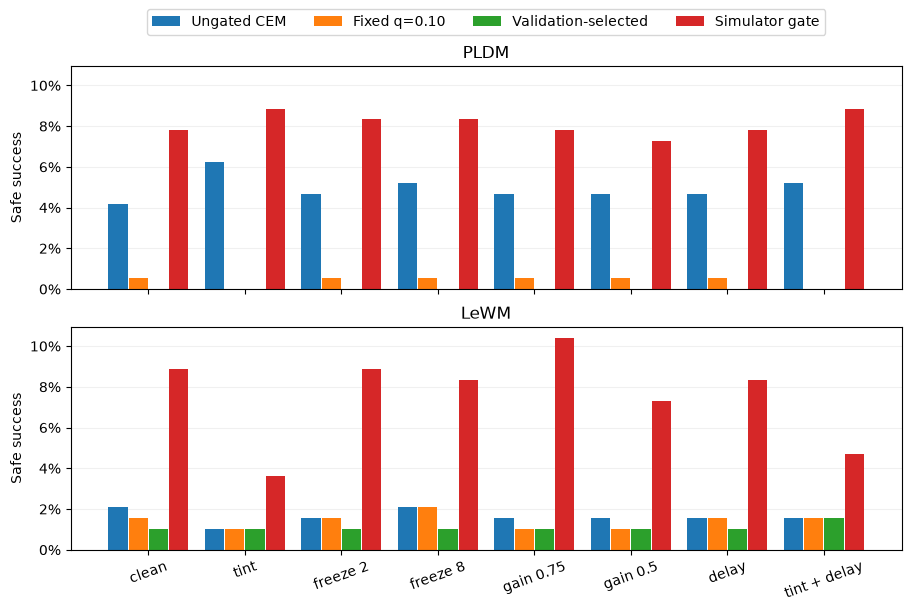

In [5]:
from matplotlib.ticker import PercentFormatter

conditions = list(dict.fromkeys(r["condition"] for r in episodes))
selected_runs = [r for r in frontier if r["selected"]]
series = {
    "Ungated CEM": [r for r in episodes if r["policy"] == "CEM"],
    "Fixed q=0.10": [r for r in episodes if r["policy"] == "learned"],
    "Validation-selected": selected_runs,
    "Simulator gate": [r for r in episodes if r["policy"] == "simulator"],
}
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True, sharey=True, layout="constrained")
for ax, model in zip(axes, ("PLDM", "LeWM")):
    for j, (label, runs) in enumerate(series.items()):
        heights = [mean([r for r in runs if (r["model"], r["condition"]) == (model, k)], "safe success") for k in conditions]
        ax.bar([i + (j - 1.5) * 0.21 for i in range(len(conditions))], heights, width=0.20, label=label)
    ax.set(ylabel="Safe success", title=model)
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.18)
axes[0].legend(ncols=4, loc="lower center", bbox_to_anchor=(0.5, 1.11))
axes[-1].set_xticks(range(len(conditions)), conditions, rotation=20)
plt.show()

In [6]:
rows = []
for model in ("PLDM", "LeWM"):
    for policy, runs in series.items():
        subset = [r for r in runs if r["model"] == model]
        if not subset:
            continue
        worst = min(conditions, key=lambda k: mean([r for r in subset if r["condition"] == k], "safe success"))
        for condition in dict.fromkeys(("clean", worst)):
            selected = [r for r in subset if r["condition"] == condition]
            rows.append([model, policy, condition, *[f"{mean(selected, metric):.1%}" for metric in ("goal reached", "safe success", "violation", "override")],
                         f"{mean(selected, 'tail penetration'):.3f}"])
table(["Model", "Gate", "Clean / lowest safe success", "Reached", "Safe success", "Violation", "Override", "Worst 10% depth"], rows)

Model | Gate | Clean / lowest safe success | Reached | Safe success | Violation | Override | Worst 10% depth
--- | --- | --- | --- | --- | --- | --- | ---
PLDM | Ungated CEM | clean | 13.5% | 4.2% | 31.8% | 0.0% | 0.072
PLDM | Fixed q=0.10 | clean | 0.5% | 0.5% | 4.7% | 63.7% | 0.008
PLDM | Fixed q=0.10 | tint | 0.0% | 0.0% | 2.6% | 78.9% | 0.006
PLDM | Validation-selected | clean | 0.0% | 0.0% | 2.6% | 69.4% | 0.004
PLDM | Simulator gate | clean | 7.8% | 7.8% | 0.0% | 23.8% | 0.000
PLDM | Simulator gate | gain 0.5 | 7.3% | 7.3% | 0.0% | 23.9% | 0.000
LeWM | Ungated CEM | clean | 23.4% | 2.1% | 84.4% | 0.0% | 0.079
LeWM | Ungated CEM | tint | 3.1% | 1.0% | 34.4% | 0.0% | 0.074
LeWM | Fixed q=0.10 | clean | 1.6% | 1.6% | 7.8% | 81.1% | 0.009
LeWM | Fixed q=0.10 | tint | 3.1% | 1.0% | 34.4% | 0.0% | 0.074
LeWM | Validation-selected | clean | 1.0% | 1.0% | 3.6% | 86.7% | 0.006
LeWM | Simulator gate | clean | 8.9% | 8.9% | 0.0% | 59.6% | 0.000
LeWM | Simulator gate | tint | 3.6% | 3.6% | 0.0% | 7.9% | 0.000

In [7]:
rows = []
for model in ("PLDM", "LeWM"):
    for label in ("Fixed q=0.10", "Validation-selected"):
        runs = [r for r in series[label] if r["model"] == model and r["condition"] == "clean"]
        cutoffs = sorted({r.get("quantile", 0.10) for r in runs})
        rows.append([model, label, ", ".join(f"{q:.2f}" for q in cutoffs), len(runs),
                     f"{mean(runs, 'violation'):.1%}", f"{mean(runs, 'safe success'):.1%}"])
table(["Model", "Operating point", "Quantile(s)", "Eligible seeds", "Clean violations", "Clean safe success"], rows)

Model | Operating point | Quantile(s) | Eligible seeds | Clean violations | Clean safe success
--- | --- | --- | --- | --- | ---
PLDM | Fixed q=0.10 | 0.10 | 3 | 4.7% | 0.5%
PLDM | Validation-selected | 0.02 | 3 | 2.6% | 0.0%
LeWM | Fixed q=0.10 | 0.10 | 3 | 7.8% | 1.6%
LeWM | Validation-selected | 0.02, 0.10 | 3 | 3.6% | 1.0%

### Inspect a paired comparison

Intervals resample whole start–goal pairs within each checkpoint. Tail depth is the mean maximum penetration across the worst seven of 64 episodes, in unit-square coordinates. The two result lists retain every condition and horizon for further analysis.

In [8]:
for r in episodes:
    if r["policy"] == "learned" and r["condition"] == "tint + delay":
        delta, low, high = r["safe delta"]
        print(f"{r['model']:5}  seed {r['seed']:2}  fixed q=0.10 safe success shift {100*delta:+.1f} pp  [95% paired interval {100*low:+.1f}, {100*high:+.1f}]")

PLDM   seed  7  fixed q=0.10 safe success shift -1.6 pp  [95% paired interval -4.7, +0.0]
LeWM   seed  7  fixed q=0.10 safe success shift +3.1 pp  [95% paired interval +0.0, +7.8]
PLDM   seed 17  fixed q=0.10 safe success shift +0.0 pp  [95% paired interval +0.0, +0.0]
LeWM   seed 17  fixed q=0.10 safe success shift -1.6 pp  [95% paired interval -4.7, +0.0]
PLDM   seed 27  fixed q=0.10 safe success shift +0.0 pp  [95% paired interval +0.0, +0.0]
LeWM   seed 27  fixed q=0.10 safe success shift -1.6 pp  [95% paired interval -4.7, +0.0]


## Choose a gate at a violation budget

Fix an episode violation budget of 10% before inspecting test outcomes. On 64 fresh validation tasks, choose the gate with the highest safe success among three cutoffs meeting the budget. Ties favor the stricter cutoff. Eligibility uses an empirical rate. The validation sample is small enough that the selected gate can exceed the budget on test.

For the combined shift, recovery means reaching the goal after the delay ends among episodes still pursuing it at step 16. Report the fraction that never reaches it within the remaining 16 steps.

In [9]:
rows = []
for seed in seeds:
    for model in ("PLDM", "LeWM"):
        selected = [r for r in frontier if r["model"] == model and r["seed"] == seed and r["selected"] and r["condition"] in ("clean", "tint + delay")]
        if not selected:
            rows.append([model, seed, "—", "No eligible gate", "—", "—", "—", "—"])
            continue
        for r in selected:
            miss = r["unrecovered"]
            rows.append([model, seed, r["quantile"], r["condition"], f"{r['validation violation']:.0%}",
                         f"{r['violation']:.0%}", f"{r['safe success']:.0%}", f"{miss:.0%}" if miss is not None else "—"])
table(["Model", "Seed", "Selected q", "Held-out condition", "Validation violation", "Test violation", "Safe success", "Unrecovered"], rows)

Model | Seed | Selected q | Held-out condition | Validation violation | Test violation | Safe success | Unrecovered
--- | --- | --- | --- | --- | --- | --- | ---
PLDM | 7 | 0.02 | clean | 6% | 3% | 0% | 100%
PLDM | 7 | 0.02 | tint + delay | 6% | 2% | 0% | 100%
LeWM | 7 | 0.1 | clean | 5% | 5% | 2% | 100%
LeWM | 7 | 0.1 | tint + delay | 5% | 33% | 5% | 97%
PLDM | 17 | 0.02 | clean | 2% | 3% | 0% | 100%
PLDM | 17 | 0.02 | tint + delay | 2% | 2% | 0% | 100%
LeWM | 17 | 0.02 | clean | 5% | 6% | 0% | 100%
LeWM | 17 | 0.02 | tint + delay | 5% | 38% | 0% | 98%
PLDM | 27 | 0.02 | clean | 3% | 2% | 0% | 100%
PLDM | 27 | 0.02 | tint + delay | 3% | 0% | 0% | 100%
LeWM | 27 | 0.02 | clean | 0% | 0% | 2% | 100%
LeWM | 27 | 0.02 | tint + delay | 0% | 36% | 0% | 97%

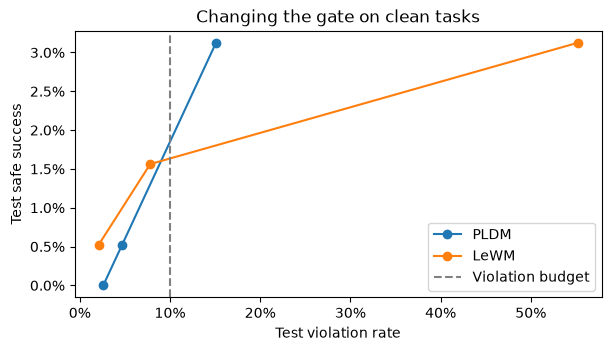

In [10]:
fig, ax = plt.subplots(figsize=(6, 3.4), layout="constrained")
for model in ("PLDM", "LeWM"):
    points = []
    for q in (0.02, 0.1, 0.5):
        subset = [r for r in frontier if (r["model"], r["quantile"], r["condition"]) == (model, q, "clean")]
        points.append((mean(subset, "violation"), mean(subset, "safe success")))
    ax.plot(*zip(*points), marker="o", label=model)
ax.axvline(0.1, color="gray", linestyle="--", label="Violation budget")
ax.set(xlabel="Test violation rate", ylabel="Test safe success", title="Changing the gate on clean tasks")
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
ax.legend()
plt.show()

## Does the action audit transfer to a robot arm?

ObstacleArm uses MuJoCo rigid-body dynamics. A hazard is either arm capsule coming within 1 cm of the obstacle box at a control endpoint. Both models are trained again on joint positions and velocities with an MLP encoder. Training, calibration and test trajectories are independently seeded. This single-seed experiment isolates action prediction with state observations. It does not establish visual transfer or physical robot performance.

In [11]:
from torch_world.benchmarks.arm_safety import run_arm_audit

arm = json.loads((Path(results_dir) / "arm.json").read_text()) if results_dir else run_arm_audit()
table(["Model", "Future", "Steps", "Unsafe candidates", "AP", "Brier"],
      [[r["model"], r["source"], r["horizon"], f"{r['unsafe count']} / {r['candidates']}",
        f"{r['average precision']:.2f}", f"{r['Brier']:.3f}"] for r in arm])

Model | Future | Steps | Unsafe candidates | AP | Brier
--- | --- | --- | --- | --- | ---
PLDM | imagined | 4 | 143 / 512 | 0.77 | 0.107
PLDM | imagined | 8 | 422 / 512 | 0.93 | 0.133
PLDM | observed | 4 | 143 / 512 | 0.81 | 0.093
PLDM | observed | 8 | 422 / 512 | 0.97 | 0.086
LeWM | imagined | 4 | 143 / 512 | 0.27 | 0.207
LeWM | imagined | 8 | 422 / 512 | 0.89 | 0.138
LeWM | observed | 4 | 143 / 512 | 0.59 | 0.155
LeWM | observed | 8 | 422 / 512 | 0.95 | 0.116